# Spadek wzdłuż gradientu (Gradient Descent)

![Góry we mgle](../obrazki/3.1_gory_mgla.png)

**Plan notatnika:**
1. Idea spadku gradientowego
2. Learning rate (współczynnik uczenia)
3. Trzy odmiany algorytmu
4. Implementacja krok po kroku
5. Wpływ learning rate – eksperyment
6. `SGDRegressor` w scikit-learn
7. Podsumowanie

## 1. Idea spadku gradientowego

Wyobraź sobie, że jesteś we mgle na szczycie i chcesz zejść do doliny. Nie widzisz całej trasy, ale czujesz nachylenie terenu pod stopami. Najrozsądniej robić małe kroki „w dół”.

**Spadek gradientowy** działa tak samo: w każdej iteracji sprawdza, w którą stronę funkcja błędu rośnie najszybciej (**gradient**), i robi krok w stronę przeciwną.

**Algorytm:**
1. Ustaw początkowe wartości parametrów (np. losowo).
2. Policz gradient funkcji kosztu $J(\mathbf{w})$.
3. Zaktualizuj parametry:

$$\mathbf{w} := \mathbf{w} - \eta \nabla J(\mathbf{w})$$

4. Powtarzaj kroki 2–3, aż parametry przestaną się zmieniać (zbieżność).

Dla regresji liniowej z funkcją kosztu MSE gradient ma postać:

$$\nabla J(\mathbf{w}) = \frac{2}{m} X^T (X\mathbf{w} - \mathbf{y})$$

$\eta$ (eta) to **learning rate**. Metoda jest przydatna, gdy danych lub cech jest dużo i równanie normalne byłoby zbyt kosztowne. Tego samego algorytmu używa się do trenowania sieci neuronowych (rozdział 5).

## 2. Learning rate (współczynnik uczenia)

Parametr $\eta$ decyduje o wielkości kroku:

![Poprawny krok](../obrazki/3.1_gd_krok.png)

**Poprawny $\eta$** – algorytm zbliża się do minimum.

![Za mały krok](../obrazki/3.1_gd_maly_krok.png)

**Za mały $\eta$** – zbieżność jest bardzo wolna.

![Za duży krok](../obrazki/3.1_gd_duzy_krok.png)

**Za duży $\eta$** – algorytm „przeskakuje” minimum i oddala się od niego (rozbieżność).

![Minima lokalne](../obrazki/3.1_gd_minima_lokalne.png)

W ogólnym przypadku funkcja kosztu może mieć minima lokalne i płaskie obszary, a algorytm utknie. **Dla regresji liniowej funkcja kosztu jest wypukła** (jedno minimum), więc poprawnie ustawiony spadek gradientowy zawsze dąży do minimum globalnego.

## 3. Trzy odmiany algorytmu

| Odmiana | Gradient liczony na | Cechy |
|---|---|---|
| **Batch** (wsadowy) | wszystkich danych | stabilny, wolny dla dużych zbiorów |
| **Stochastic** (SGD) | jednej losowej obserwacji | szybki, ale „szarpany” |
| **Mini-batch** | małej paczce danych (np. 32) | kompromis, standard w sieciach neuronowych |

W tym notatniku implementujemy wersję batch, a następnie używamy `SGDRegressor` ze scikit-learn.

## 4. Implementacja krok po kroku

Używamy tych samych danych co w notatniku 01 (wynagrodzenie vs lata pracy). Znamy poprawną odpowiedź: $w_0 = 2750$, $w_1 = 250$.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

lata_pracy = np.array([1, 2, 3, 4, 5, 6])
Y = np.array([3000, 3250, 3500, 3750, 4000, 4250]).reshape(-1, 1)
m = len(lata_pracy)

X1 = lata_pracy.reshape(m, 1)
X = np.hstack([np.ones((m, 1)), X1])    # kolumna jedynek + cecha

print(X.shape, Y.shape)

(6, 2) (6, 1)


In [3]:
X

array([[1., 1.],
       [1., 2.],
       [1., 3.],
       [1., 4.],
       [1., 5.],
       [1., 6.]])

In [5]:
Y

array([[3000],
       [3250],
       [3500],
       [3750],
       [4000],
       [4250]])

**Losowa inicjalizacja parametrów** i pętla spadku gradientowego. W każdej iteracji:
1. liczymy gradient: `(2 / m) * X.T @ (X @ weights - Y)`,
2. przesuwamy parametry w przeciwną stronę, o krok `eta * gradient`.

Zapisujemy też historię parametrów, aby zobaczyć, jak model się uczy.

In [9]:
weights = rng.normal(size=(2, 1)) 

In [11]:
rng = np.random.default_rng(42)
weights = rng.normal(size=(2, 1))     # losowe w0 i w1
eta = 0.01                            # learning rate
history = []

for i in range(3000):
    gradient = (2 / m) * X.T @ (X @ weights - Y)
    weights = weights - eta * gradient
    history.append(weights.ravel())

history = np.array(history)
print(f'Parametry po 3000 iteracjach: w0 = {weights[0, 0]:.2f}, w1 = {weights[1, 0]:.2f}')

Parametry po 3000 iteracjach: w0 = 2749.96, w1 = 250.01


In [12]:
weights

array([[2749.95600921],
       [ 250.01027535]])

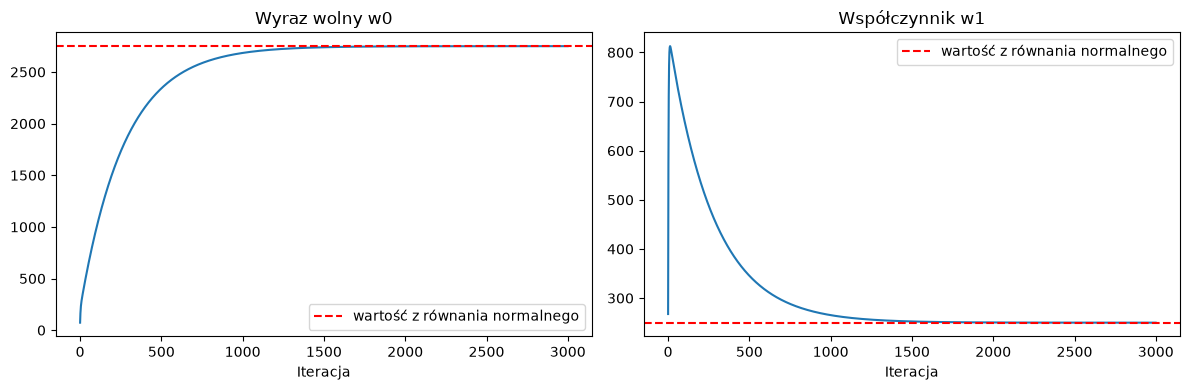

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history[:, 0])
axes[0].axhline(2750, color='red', linestyle='--', label='wartość z równania normalnego')
axes[0].set_title('Wyraz wolny w0')
axes[0].set_xlabel('Iteracja')
axes[0].legend()

axes[1].plot(history[:, 1])
axes[1].axhline(250, color='red', linestyle='--', label='wartość z równania normalnego')
axes[1].set_title('Współczynnik w1')
axes[1].set_xlabel('Iteracja')
axes[1].legend()

plt.tight_layout()
plt.show()

Parametry zbliżają się do wartości z równania normalnego. Na początku zmiany są duże (stromy fragment funkcji kosztu), potem coraz mniejsze.

## 5. Wpływ learning rate – eksperyment

Uruchomimy ten sam algorytm z czterema wartościami $\eta$, zaczynając od tych samych parametrów. Na wykresie widać **błąd MSE** w kolejnych iteracjach (skala logarytmiczna).

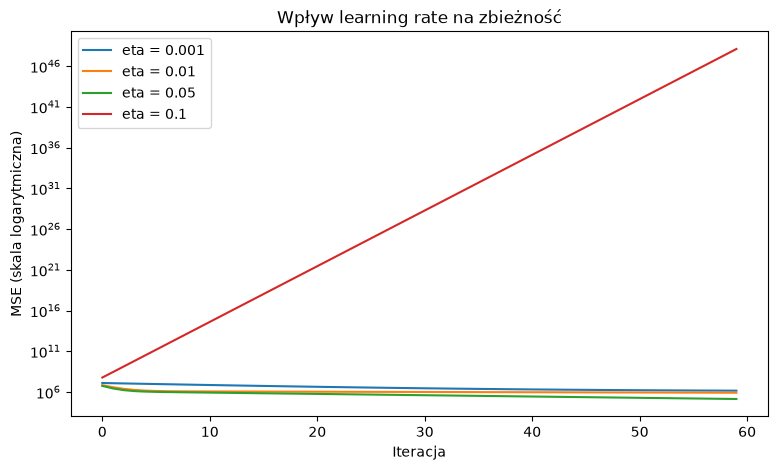

In [13]:
def gradient_descent(eta, n_iter, w_start):
    w = w_start.copy()
    losses = []
    for _ in range(n_iter):
        w = w - eta * (2 / m) * X.T @ (X @ w - Y)
        losses.append(np.mean((X @ w - Y) ** 2))
    return w, losses

w_start = np.random.default_rng(42).normal(size=(2, 1))

plt.figure(figsize=(9, 5))
for eta in [0.001, 0.01, 0.05, 0.1]:
    _, losses = gradient_descent(eta, 60, w_start)
    plt.plot(losses, label=f'eta = {eta}')

plt.yscale('log')
plt.xlabel('Iteracja')
plt.ylabel('MSE (skala logarytmiczna)')
plt.title('Wpływ learning rate na zbieżność')
plt.legend()
plt.show()

**Wnioski:**
- `eta = 0.001` – błąd maleje, ale bardzo wolno,
- `eta = 0.01` i `0.05` – błąd szybko spada,
- `eta = 0.1` – błąd **rośnie**: algorytm się rozbiega.

Zbyt duży $\eta$ uniemożliwia naukę. Zbyt mały wymaga bardzo wielu iteracji. Przy cechach o różnych skalach dobór $\eta$ jest trudniejszy, dlatego przed spadkiem gradientowym **skalujemy cechy** (notatnik 2.4/01).

## 6. `SGDRegressor` w scikit-learn

`SGDRegressor` uczy regresję liniową metodą stochastycznego spadku gradientowego. Parametry:
- `eta0` – początkowy learning rate,
- `max_iter` – maksymalna liczba przebiegów po danych,
- `tol` – próg zatrzymania, gdy błąd przestaje się zmniejszać,
- `penalty=None` – bez regularyzacji (czysta regresja liniowa).

In [14]:
from sklearn.linear_model import SGDRegressor

sgd_reg = SGDRegressor(max_iter=10000, penalty=None, eta0=0.01, tol=1e-5, random_state=42)
sgd_reg.fit(X1, Y.ravel())

print(f'intercept_ = {sgd_reg.intercept_[0]:.2f}')
print(f'coef_      = {sgd_reg.coef_[0]:.2f}')

intercept_ = 2749.75
coef_      = 250.06


Wynik jest bliski 2750 i 250, ale nie identyczny. Algorytm jest stochastyczny i zatrzymuje się po spełnieniu warunku `tol`.

## 7. Podsumowanie

1. Spadek gradientowy iteracyjnie poprawia parametry modelu, idąc w stronę przeciwną do gradientu.
2. Kluczowe elementy: gradient, learning rate $\eta$, liczba iteracji.
3. Zbyt duży $\eta$ powoduje rozbieżność, zbyt mały – bardzo wolną naukę.
4. Dla regresji liniowej funkcja kosztu jest wypukła, więc metoda znajduje minimum globalne.
5. Wynik jest zbliżony do równania normalnego. Zalety spadku gradientowego widać przy dużych danych i w sieciach neuronowych.